In [1]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import os
import time
from sklearn import metrics
from torch.optim.lr_scheduler import LambdaLR


from scipy.interpolate import CubicSpline

In [2]:
def splineSpectr(df1,xs,normalize=True):
    cs = CubicSpline(df1.wavelength, df1.intensity)    
    ys=cs(xs)
    if normalize==True:
        normalizedData = (ys-np.min(ys))/(np.max(ys)-np.min(ys))
        return normalizedData
    return ys

def readFile(path,xs):
    df=pd.read_csv(path)
    return splineSpectr(df,xs)

def retY(fileName,metaDF):
    res=metaDF[metaDF['sample_id']==fileName]
    del res['sample_id']
    wyn=res.to_numpy()
    wyn=wyn[0]/100.0
    return wyn

In [3]:
metadataPath='C:\\Users\\Tomek_\\Downloads\\metadata.csv'
mdf=pd.read_csv(metadataPath)
mdf.head()


dataCSVPath='C:\\Users\\Tomek_\\Downloads\\spectra50k\\para1\\'






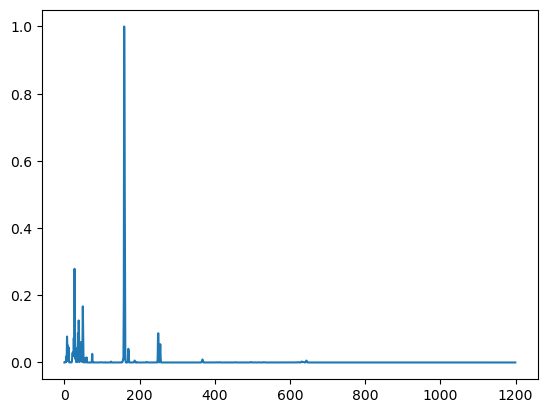

In [4]:
sample='Mg10.32_N49.98_Cu39.7.csv'
xs = np.arange(200, 800, 0.5)
wyn=readFile(dataCSVPath+sample,xs)
plt.plot(wyn)

In [5]:
import torch
from torch.utils.data import Dataset

class CustomDataset(Dataset):
    def __init__(self, torchX, torchY, transform=None):
        self.X = torchX;
        self.Y = torchY;
   

    def __len__(self):
        return len(self.X)

    
    def __getitem__(self, idx):
        sampleX = self.X[idx]
        sampleY=self.Y[idx]    
        return sampleX,sampleY

In [7]:
iter=0;
xs = np.arange(200, 800, 0.5)
trainSize=15000

for x in os.listdir(dataCSVPath):
    if iter%1000==0:
        print("przeanalizowano "+str(iter)+" plików")
    if iter<trainSize:
        if x.endswith(".csv"):
            tempX=readFile(dataCSVPath+x,xs)
            tempY=retY(x,mdf)
            if iter==0:
                X=tempX;
                Y=tempY;
            else:
                X=np.vstack([X,tempX])
                Y=np.vstack([Y,tempY])   
            iter+=1;
    elif iter>=trainSize and iter<trainSize+1000:
        if x.endswith(".csv"):
            tempX=readFile(dataCSVPath+x,xs)
            tempY=retY(x,mdf)
            if iter==trainSize:
                Xtest=tempX;
                Ytest=tempY;
            else:
                Xtest=np.vstack([Xtest,tempX])
                Ytest=np.vstack([Ytest,tempY])   
            iter+=1;
    else:
        break

tensX = torch.Tensor(X)
tensY = torch.Tensor(Y)
tensXtest = torch.Tensor(Xtest)
tensYtest = torch.Tensor(Ytest)

przeanalizowano 0 plików
przeanalizowano 1000 plików
przeanalizowano 2000 plików
przeanalizowano 3000 plików
przeanalizowano 4000 plików
przeanalizowano 5000 plików
przeanalizowano 6000 plików
przeanalizowano 7000 plików
przeanalizowano 8000 plików
przeanalizowano 9000 plików
przeanalizowano 10000 plików
przeanalizowano 11000 plików
przeanalizowano 12000 plików
przeanalizowano 13000 plików
przeanalizowano 14000 plików
przeanalizowano 15000 plików
przeanalizowano 16000 plików


In [8]:
train_data = CustomDataset(tensX, tensY)
batch_size=128
train_dataloader = DataLoader(dataset=train_data, batch_size=batch_size, shuffle=True)





In [9]:
for batch, (X, y) in enumerate(train_dataloader):
    print(f"Batch: {batch+1}")
    print(f"X shape: {X.shape}")
    print(f"y shape: {y.shape}")
    break

Batch: 1
X shape: torch.Size([128, 1200])
y shape: torch.Size([128, 10])


In [10]:
#pierwsze próby sieć gęsta bez warstwy konwolucyjnej
import torch
from torch import nn
from torch import optim

input_dim = 200
hidden_dim = [50,20,10]
output_dim = 10

class NeuralNetwork(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(NeuralNetwork, self).__init__()
        self.layer_1 = nn.Linear(input_dim, hidden_dim[0])
        nn.init.kaiming_uniform_(self.layer_1.weight, nonlinearity="relu")
        self.layer_2 = nn.Linear(hidden_dim[0], hidden_dim[1])
        nn.init.kaiming_uniform_(self.layer_2.weight, nonlinearity="relu")
        self.layer_3 = nn.Linear(hidden_dim[1], hidden_dim[2])
        nn.init.kaiming_uniform_(self.layer_3.weight, nonlinearity="relu")
        self.layer_last = nn.Linear(hidden_dim[2], output_dim)
       
    def forward(self, x):
        x = torch.nn.functional.relu(self.layer_1(x))
        x = torch.nn.functional.relu(self.layer_2(x))
        x = torch.nn.functional.relu(self.layer_3(x))
        x = torch.nn.functional.sigmoid(self.layer_last(x))
      
        return x
       
model = NeuralNetwork(input_dim, hidden_dim, output_dim)
print(model)


NeuralNetwork(
  (layer_1): Linear(in_features=200, out_features=50, bias=True)
  (layer_2): Linear(in_features=50, out_features=20, bias=True)
  (layer_3): Linear(in_features=20, out_features=10, bias=True)
  (layer_last): Linear(in_features=10, out_features=10, bias=True)
)


In [ ]:
learning_rate = 0.00001
loss_fn = nn.L1Loss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

In [ ]:
num_epochs = 50
loss_values = []


for epoch in range(num_epochs):
    print("epoch"+ str(epoch))
    for X, y in train_dataloader:
        # zero the parameter gradients
        optimizer.zero_grad()
       
        # forward + backward + optimize
        pred = model(X)
        
        loss = loss_fn(pred, y)
        loss_values.append(loss.item())
        loss.backward()
        optimizer.step()
        
    print(loss)
print("Training Complete")

In [ ]:
step = range(len(loss_values))

fig, ax = plt.subplots(figsize=(8,5))
plt.plot(step, np.array(loss_values))
plt.title("Step-wise Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

In [101]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
import torch.optim.lr_scheduler as lr_scheduler

# ===== Model =====
class SimpleCNN1D(nn.Module):
    def __init__(self):
        super(SimpleCNN1D, self).__init__()
        
        self.conv1 = nn.Conv1d(1, 16, kernel_size=9)
        self.conv2 = nn.Conv1d(16, 10, kernel_size = 7)

        # 200 -> 196
        self.flatten_size = 10 * 1186
        
     
        # NOWE warstwy ukryte
        self.fc1 = nn.Linear(self.flatten_size, 20)
        self.fc2 = nn.Linear(20, 10)
        
        # warstwa wyjściowa (10 wartości)
        self.fc3 = nn.Linear(10, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = x.view(x.size(0), -1)
        
        # przejście przez nowe warstwy
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        
        x = self.fc3(x)
        
        return x


# ===== Dane (sztuczne) =====
# 1000 próbek
#X = torch.randn(1000, 1, 200)

X=tensX.reshape(tensX.shape[0],1,1200)
#y = torch.randn(1000, 10)
y=tensY
# ===== Model, loss, optimizer =====
model = SimpleCNN1D()

criterion = nn.MSELoss()  # regresja
optimizer = optim.Adam(model.parameters(), lr=0.001)
#scheduler = lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
#scheduler = LambdaLR(optimizer, lr_lambda=lambda epoch: 0.95 ** (epoch+1))
#scheduler = lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.1, total_iters=20)
# ===== Trening =====
epochs = 50
batch_size = 256
losses=[]
for epoch in range(epochs):
    permutation = torch.randperm(X.size(0))
    
    epoch_loss = 0.0
    
    for i in range(0, X.size(0), batch_size):
        indices = permutation[i:i+batch_size]
        batch_x = X[indices]
        batch_y = y[indices]
        
        # forward
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        
        # backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        #scheduler.step();
        
        epoch_loss += loss.item()
    
    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f},")#  LR: {lr_scheduler.get_last_lr():.4f}")
    losses.append(epoch_loss)

# ===== Test =====
test_input = torch.randn(1, 1, 1200)
prediction = model(test_input)

print("Predykcja:", prediction)

Epoch 1/50, Loss: 3.0367,
Epoch 2/50, Loss: 1.7840,
Epoch 3/50, Loss: 1.6406,
Epoch 4/50, Loss: 1.5395,
Epoch 5/50, Loss: 1.4784,
Epoch 6/50, Loss: 1.4273,
Epoch 7/50, Loss: 1.3809,
Epoch 8/50, Loss: 1.3380,
Epoch 9/50, Loss: 1.3026,
Epoch 10/50, Loss: 1.2724,
Epoch 11/50, Loss: 1.2432,
Epoch 12/50, Loss: 1.2215,
Epoch 13/50, Loss: 1.2014,
Epoch 14/50, Loss: 1.1879,
Epoch 15/50, Loss: 1.1708,
Epoch 16/50, Loss: 1.1541,
Epoch 17/50, Loss: 1.1395,
Epoch 18/50, Loss: 1.1154,
Epoch 19/50, Loss: 1.0888,
Epoch 20/50, Loss: 1.0618,
Epoch 21/50, Loss: 1.0334,
Epoch 22/50, Loss: 1.0088,
Epoch 23/50, Loss: 0.9911,
Epoch 24/50, Loss: 0.9754,
Epoch 25/50, Loss: 0.9610,
Epoch 26/50, Loss: 0.9585,
Epoch 27/50, Loss: 0.9440,
Epoch 28/50, Loss: 0.9392,
Epoch 29/50, Loss: 0.9301,
Epoch 30/50, Loss: 0.9274,
Epoch 31/50, Loss: 0.9194,
Epoch 32/50, Loss: 0.9118,
Epoch 33/50, Loss: 0.9083,
Epoch 34/50, Loss: 0.9034,
Epoch 35/50, Loss: 0.8970,
Epoch 36/50, Loss: 0.8911,
Epoch 37/50, Loss: 0.8896,
Epoch 38/5

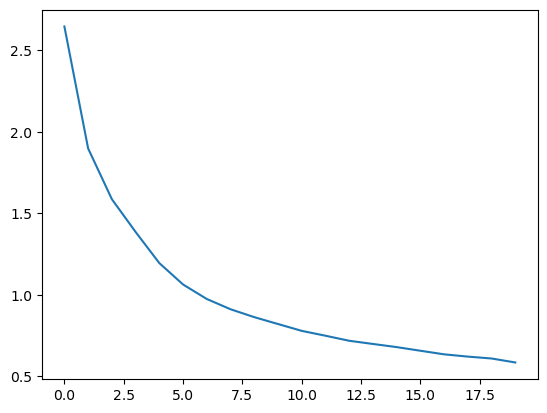

In [79]:
plt.plot(losses)

In [84]:
torch.save(model.state_dict(), 'model_weights.pth')


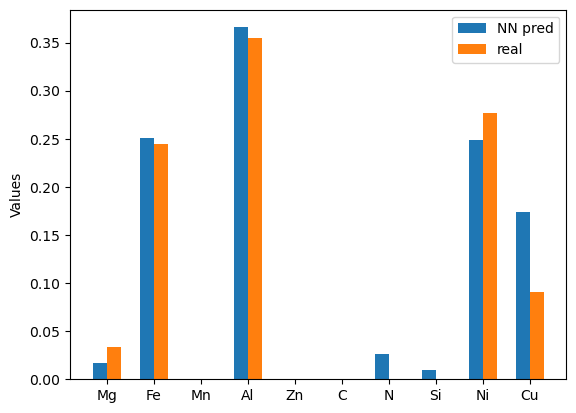

In [83]:
import random


i=random.randrange(0, 100)

A=tensXtest[0:100,:]
A=A.reshape(A.shape[0],1,1200);
B=tensYtest[0:100,:]
pred=model(A)[i].detach().numpy()
pred[pred < 0] = 0
real=B[i].detach().numpy()


cats = ['Mg','Fe','Mn','Al','Zn','C','N','Si','Ni','Cu'] 
w, x = 0.3, np.arange(len(cats))
fig, ax = plt.subplots()
ax.bar(x - w/2, pred, width=w, label='NN pred')
ax.bar(x + w/2, real, width=w, label='real')

ax.set_xticks(x)
ax.set_xticklabels(cats)
ax.set_ylabel('Values')
ax.set_title('')
ax.legend()

In [12]:
print(tensX.shape)

torch.Size([15000, 1200])


In [85]:
class SimpleCNN1D(nn.Module):
    def __init__(self):
        super(SimpleCNN1D, self).__init__()
        
        self.conv1 = nn.Conv1d(1, 16, kernel_size=9)
        self.conv2 = nn.Conv1d(16, 10, kernel_size = 7)

        # 200 -> 196
        self.flatten_size = 10 * 1186
        
     
        # NOWE warstwy ukryte
        self.fc1 = nn.Linear(self.flatten_size, 20)
        self.fc2 = nn.Linear(20, 10)
        
        # warstwa wyjściowa (10 wartości)
        self.fc3 = nn.Linear(10, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = x.view(x.size(0), -1)
        
        # przejście przez nowe warstwy
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        
        x = self.fc3(x)
        
        return x


In [99]:
m1=SimpleCNN1D()
m1=model.load_state_dict(torch.load('model_weights.pth'))


TypeError: '_IncompatibleKeys' object is not callable

<All keys matched successfully>
